In [29]:
import tensorflow as tf
from tensorflow.keras import layers,models
from pathlib import Path
import numpy as np
from tensorflow.keras import layers,models


# les class
PROJECT_DIR = Path("/kaggle/working/brainscan")

SPLIT_DIR = Path("/kaggle/input/datasets/brainscan/data_split/data_split")

TRAIN_DIR = SPLIT_DIR / "train"
VAL_DIR = SPLIT_DIR / "val"
TEST_DIR = SPLIT_DIR / "test"

class_names = sorted(
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
)

num_class = len(class_names)
#params du model
image_size=(299,299)
batch_size=16
seed=42 

print("Classes :", class_names)
print("Nombre de classes :", num_class)
print("Dossier Train existe :", TRAIN_DIR.exists())


print("Classes :", class_names)
print("Nombre de classes :", num_class)
print("Taille des images :", image_size)

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
Nombre de classes : 4
Dossier Train existe : True
Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
Nombre de classes : 4
Taille des images : (299, 299)


In [30]:
# chargement des imgs
train_ds =tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names=class_names,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int",
    color_mode="rgb",
    shuffle=True,
    seed=seed
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    class_names=class_names,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=class_names,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int",
    color_mode="rgb",
    shuffle=False
)

Found 4708 files belonging to 4 classes.
Found 1009 files belonging to 4 classes.
Found 1009 files belonging to 4 classes.


In [32]:
# pre
def preprocess_imgs(images,labels):
    images = tf.keras.applications.inception_v3.preprocess_input(
        tf.cast(images,tf.float32)
    )
    return images,labels

train_ds = train_ds.map(
    preprocess_imgs,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    preprocess_imgs,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preprocess_imgs,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [5]:
# charger les inception-v3
base_model = tf.keras.applications.InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299,299,3)
)

base_model.trainable=False
print("nbr de couches :",len(base_model.layers))

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
nbr de couches : 311


In [6]:
# modification dans couche dense
inputs = layers.Input(shape=(299,299,3))

x = base_model(inputs,training=False)
x =layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_class,
    activation="softmax"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [7]:
# compiler le model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [8]:
# virifier les donne et les sortie du model
# recuperer un seul batch

for images,labels in train_ds.take(1):#un seul batch
    print("forme des images :", images.shape)
    print("forme des labels :", labels.shape)
    print("valeur minimale :",tf.reduce_min(images).numpy())
    print("valeur maximale :",tf.reduce_max(images).numpy())

    prediction = model(images,training=False)
    print("forme des prediction :",prediction.shape)

forme des images : (16, 299, 299, 3)
forme des labels : (16,)
valeur minimale : -1.0
valeur maximale : 1.0
forme des prediction : (16, 4)


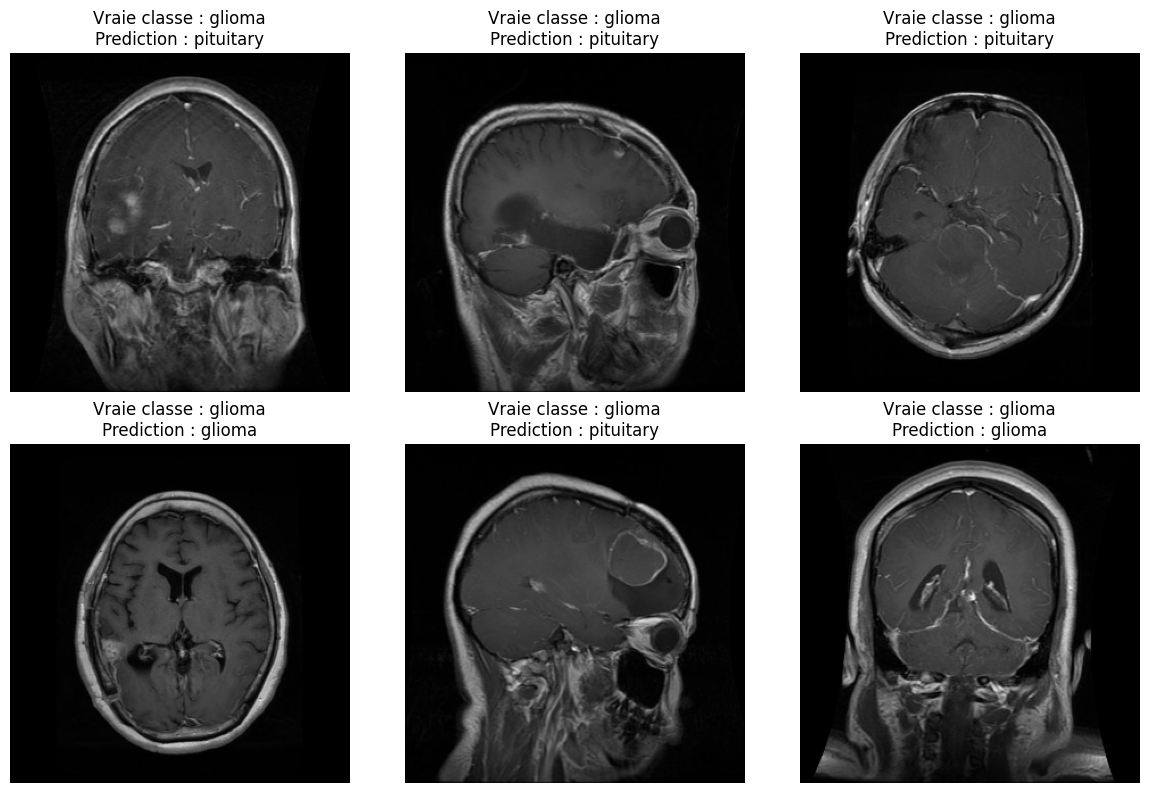

In [9]:
import matplotlib.pyplot as plt
import numpy as np

for images,labels in test_ds.take(1):
    predictions=model.predict(images,verbose=0)

    predicted_classes=np.argmax(predictions,axis=1)

    plt.figure(figsize=(12,8))

    for i in range(min(6,len(images))):
        # annuler les pretraitement pour afficher les imgs
        image = (images[i] + 1.0)/2.0
        image = np.clip(image,0.0,1.0)

        true_class = class_names[int(labels[i].numpy())]
        predicted_class = class_names[predicted_classes[i]]

        plt.subplot(2,3,i+1)
        plt.imshow(image)
        plt.title(
            f"Vraie classe : {true_class}\n"
            f"Prediction : {predicted_class}"
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
# une petit train

history_test = model.fit(
    train_ds.take(2),
    validation_data=val_ds.take(1),
    epochs=1
)


2/2 ━━━━━━━━━━━━━━━━━━━━ 17s 7s/step - accuracy: 0.2500 - loss: 1.3691 - val_accuracy: 0.0625 - val_loss: 1.7550


In [11]:
model_dir = PROJECT_DIR / "models"
model_dir.mkdir(parents=True,exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_dir / "inceptionv3_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        str(model_dir / "inceptionv3_training.csv")
    )
]


In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)
# 74 min44intr

Epoch 1/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6670 - loss: 0.7990
Epoch 1: val_loss improved from None to 0.39461, saving model to /kaggle/working/brainscan/models/inceptionv3_best.keras

Epoch 1: finished saving model to /kaggle/working/brainscan/models/inceptionv3_best.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 687s 2s/step - accuracy: 0.7640 - loss: 0.6026 - val_accuracy: 0.8553 - val_loss: 0.3946
Epoch 2/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8450 - loss: 0.4036
Epoch 2: val_loss improved from 0.39461 to 0.34425, saving model to /kaggle/working/brainscan/models/inceptionv3_best.keras

Epoch 2: finished saving model to /kaggle/working/brainscan/models/inceptionv3_best.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 707s 2s/step - accuracy: 0.8539 - loss: 0.3810 - val_accuracy: 0.8751 - val_loss: 0.3443
Epoch 3/10
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8803 - loss: 0.3170
Epoch 3: val_loss improved from 0.34425 to 0.30653, saving model to /kaggle/workin

In [13]:
# PROJECT_DIR = "/kaggle/working"
# import joblib 
# testmodel=
# joblib.dump(os.path.join(PROJECT_DIR,"test.keras"))

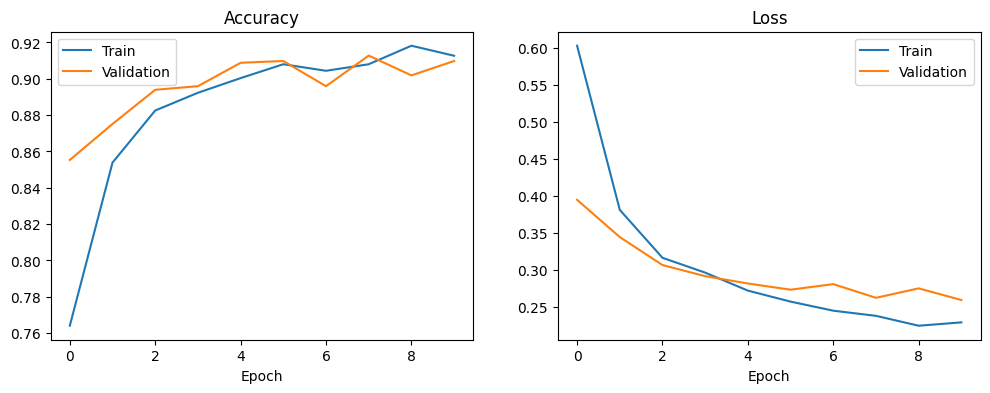

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history["accuracy"],label="Train")
plt.plot(history.history["val_accuracy"],label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

In [15]:
# evaluation du model
import tensorflow as tf
model = tf.keras.models.load_model(
    PROJECT_DIR / "models" / "inceptionv3_best.keras"
)

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print(f"test accuracy : {test_accuracy * 100:.2f}%")
print(f"test loss : {test_loss:.4f}")

64/64 ━━━━━━━━━━━━━━━━━━━━ 125s 2s/step - accuracy: 0.9019 - loss: 0.2547
test accuracy : 90.19%
test loss : 0.2547


In [ ]:
# les prediction des image de test
prediction = model.predict(test_ds,verbose=1)
print("forme des prediction :",prediction.shape)

59/64 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step 

In [33]:
y_pre = np.argmax(prediction,axis=1) #argmax => cherche la position de la probabilite la plus elevee
print(y_pre[:10])

prediction_class = [
    class_names[index]
    for index in y_pre
]
print(prediction_class[:10])

[0 0 0 1 0 0 0 0 0 0]
['glioma', 'glioma', 'glioma', 'meningioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma', 'glioma']


In [34]:
# comparer
y_true = np.concatenate([
    labels.numpy()
    for images,labels in test_ds
])
print(y_true.shape)
print(y_true [:10])

(1009,)
[0 0 0 0 0 0 0 0 0 0]


In [35]:
# la matice de confusion
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(
    y_true,
    y_pre,
    labels=[0,1,2,3]
)

print(cm)


[[209  32   0   2]
 [ 14 209   5  18]
 [  1  14 243   1]
 [  2  10   0 249]]


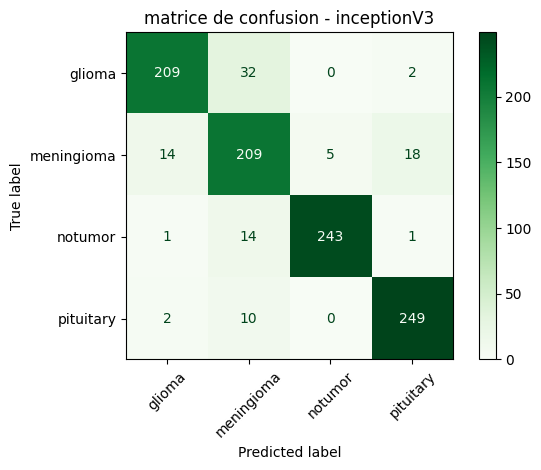

In [36]:
# la matrice avec les nom des class
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Greens",values_format="d")

plt.title("matrice de confusion - inceptionV3")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
# les autre metric
report = classification_report(
    y_true,
    y_pre,
    labels=[0,1,2,3],
    target_names=class_names,
    digits=4,
    zero_division=0
)
print(report)

              precision    recall  f1-score   support

      glioma     0.9248    0.8601    0.8913       243
  meningioma     0.7887    0.8496    0.8180       246
     notumor     0.9798    0.9382    0.9586       259
   pituitary     0.9222    0.9540    0.9379       261

    accuracy                         0.9019      1009
   macro avg     0.9039    0.9005    0.9014      1009
weighted avg     0.9051    0.9019    0.9027      1009



In [38]:
import pandas as pd
results_path = PROJECT_DIR / "reports" / "test_predictions.csv"
results_path.parent.mkdir(parents=True, exist_ok=True)

report_dict = classification_report(
    y_true,
    y_pre,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# dictionnaire -> tableau
metrics_df = pd.DataFrame(report_dict).transpose()

metrics_path = PROJECT_DIR / "reports" / "test_metrics.csv"
metrics_df.to_csv(metrics_path, index=True)

print(metrics_df)

              precision    recall  f1-score      support
glioma         0.924779  0.860082  0.891258   243.000000
meningioma     0.788679  0.849593  0.818004   246.000000
notumor        0.979839  0.938224  0.958580   259.000000
pituitary      0.922222  0.954023  0.937853   261.000000
accuracy       0.901883  0.901883  0.901883     0.901883
macro avg      0.903880  0.900481  0.901424  1009.000000
weighted avg   0.905069  0.901883  0.902732  1009.000000


In [39]:
model = tf.keras.models.load_model(
    PROJECT_DIR / "models" / "inceptionv3_best.keras"
)

print("modele charge.")
print("accuracy de reference sur validation :")

val_loss, val_accuracy = model.evaluate(
    val_ds,
    verbose=1
)

print(f"validation accuracy : {val_accuracy * 100:.2f}%")
print(f"validation loss : {val_loss:.4f}")

modele charge.
accuracy de reference sur validation :
64/64 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.2507 - loss: 4.2897
validation accuracy : 25.07%
validation loss : 4.2897


In [40]:
# fineTuning

base_model = model.get_layer("inception_v3")

base_model.trainable = True #autoriser le fine-tuning

for layer in base_model.layers[:-30]:#garder les premier couche gelees
    layer.trainable = False

trainable_layers=sum(
    1 for layer in base_model.layers
    if layer.trainable
)


print("nombre total de couches :", len(base_model.layers))
print("nombre de couches entrainables :", trainable_layers)

nombre total de couches : 311
nombre de couches entrainables : 30


In [41]:
model.compile(
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [43]:
fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            PROJECT_DIR / "models" / "inceptionv3_finetuned_best.keras"
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        str(
            PROJECT_DIR / "models" / "inceptionv3_finetuning.csv"
        )
    )
]

In [44]:
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=fine_tune_callbacks
)

Epoch 1/5
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.4933 - loss: 1.5413
Epoch 1: val_loss improved from None to 0.67669, saving model to /kaggle/working/brainscan/models/inceptionv3_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/brainscan/models/inceptionv3_finetuned_best.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 778s 3s/step - accuracy: 0.5945 - loss: 1.1036 - val_accuracy: 0.7007 - val_loss: 0.6767
Epoch 2/5
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7085 - loss: 0.6922
Epoch 2: val_loss improved from 0.67669 to 0.49431, saving model to /kaggle/working/brainscan/models/inceptionv3_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/brainscan/models/inceptionv3_finetuned_best.keras
295/295 ━━━━━━━━━━━━━━━━━━━━ 781s 3s/step - accuracy: 0.7271 - loss: 0.6562 - val_accuracy: 0.8018 - val_loss: 0.4943
Epoch 3/5
295/295 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7679 - loss: 0.5566
Epoch 3: val_loss improved from 0.49431 to 0.

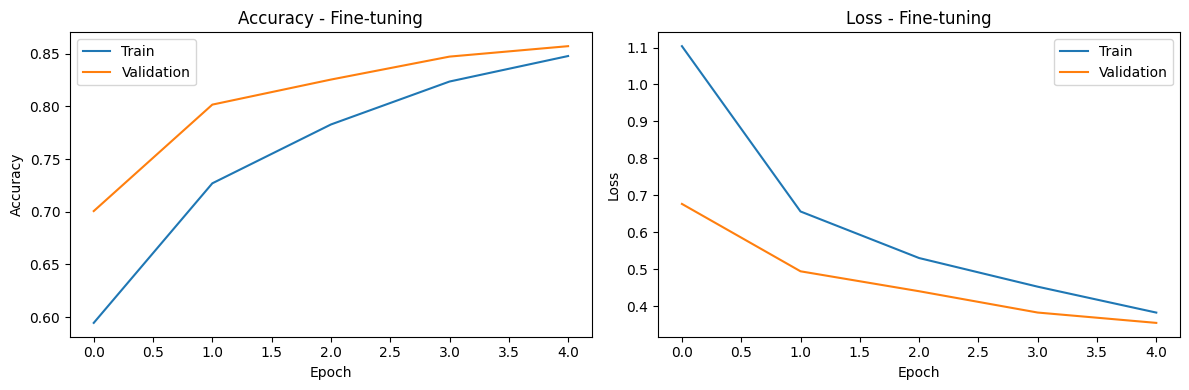

In [45]:
import matplotlib.pyplot as plt

history_data = history_finetune.history

plt.figure(figsize=(12, 4))

# courbe de l'accuracy
plt.subplot(1, 2, 1)
plt.plot(history_data["accuracy"], label="Train")
plt.plot(history_data["val_accuracy"], label="Validation")
plt.title("Accuracy - Fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# courbe de la loss
plt.subplot(1, 2, 2)
plt.plot(history_data["loss"], label="Train")
plt.plot(history_data["val_loss"], label="Validation")
plt.title("Loss - Fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [46]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

print("Dossiers disponibles dans /kaggle/input :")

for path in INPUT_DIR.rglob("*"):
    if path.is_dir() and path.name in ["train", "val", "test"]:
        print(path)

Dossiers disponibles dans /kaggle/input :
/kaggle/input/datasets/brainscan/data_split/data_split/val
/kaggle/input/datasets/brainscan/data_split/data_split/test
/kaggle/input/datasets/brainscan/data_split/data_split/train


In [48]:
MODEL_PATH = PROJECT_DIR / "models" / "inceptionv3_finetuned_best.keras"
model = tf.keras.models.load_model(MODEL_PATH)

In [49]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("evaluation finale :")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

64/64 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.8474 - loss: 0.3743
evaluation finale :
Test Loss     : 0.3743
Test Accuracy : 84.74%


In [50]:
import numpy as np

predictions = model.predict(test_ds, verbose=1)

y_pred = np.argmax(predictions, axis=1)

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

print("Nombre de predictions :", len(y_pred))
print("Nombre de vraies classes :", len(y_true))

64/64 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step
Nombre de predictions : 1009
Nombre de vraies classes : 1009


In [51]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("classification report :")
print(report)

classification report :
              precision    recall  f1-score   support

      glioma     0.7787    0.8107    0.7944       243
  meningioma     0.7908    0.6301    0.7014       246
     notumor     0.9321    0.9537    0.9427       259
   pituitary     0.8678    0.9808    0.9209       261

    accuracy                         0.8474      1009
   macro avg     0.8423    0.8438    0.8398      1009
weighted avg     0.8441    0.8474    0.8425      1009



<Figure size 900x700 with 0 Axes>

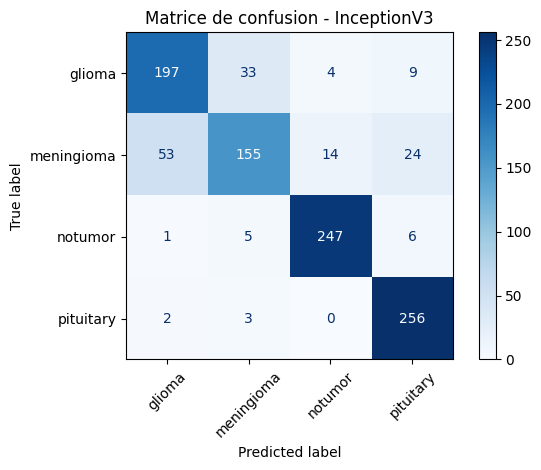

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

plt.figure(figsize=(9, 7))
disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - InceptionV3")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [53]:
import pandas as pd

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = []

for class_name in class_names:
    class_dir = TEST_DIR / class_name

    files = sorted([
        path for path in class_dir.iterdir()
        if path.is_file() and path.suffix.lower() in image_extensions
    ])

    image_paths.extend(files)

assert len(image_paths) == len(y_true) == len(y_pred), (
    "Le nombre de chemins ne correspond pas au nombre de predictions."
)

resultat = pd.DataFrame({
    "image_path": [str(path) for path in image_paths],
    "true_label": [class_names[i] for i in y_true],
    "predicted_label": [class_names[i] for i in y_pred],
    "correct": (y_true == y_pred)
})

display(resultat.head(10))

,image_path,true_label,predicted_label,correct
0,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True
1,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True
2,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True
3,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True
4,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True
5,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True
6,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True
7,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True
8,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,pituitary,False
9,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,glioma,True


In [54]:
errors = resultat[resultat["correct"] == False]

print("nombre d'erreurs :", len(errors))
print("nombre de predictions correctes :", resultat["correct"].sum())

display(errors.head(10))

nombre d'erreurs : 154
nombre de predictions correctes : 855


,image_path,true_label,predicted_label,correct
8,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,pituitary,False
11,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,meningioma,False
13,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,meningioma,False
19,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,pituitary,False
21,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,meningioma,False
30,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,notumor,False
32,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,meningioma,False
35,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,meningioma,False
53,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,meningioma,False
68,/kaggle/input/datasets/mariaelgotby/data-split...,glioma,pituitary,False


In [55]:
REPORT_DIR = PROJECT_DIR / "report"
MODEL_DIR = PROJECT_DIR / "models"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

resultat.to_csv(
    REPORT_DIR / "test_predictions.csv",
    index=False
)

with open(REPORT_DIR / "classification_report.txt", "w") as file:
    file.write(report)

metrics = pd.DataFrame([{
    "model": "InceptionV3",
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "total_images": len(y_true),
    "correct_predictions": int((y_true == y_pred).sum()),
    "incorrect_predictions": int((y_true != y_pred).sum())
}])

metrics.to_csv(
    REPORT_DIR / "test_metrics.csv",
    index=False
)


<Figure size 900x700 with 0 Axes>

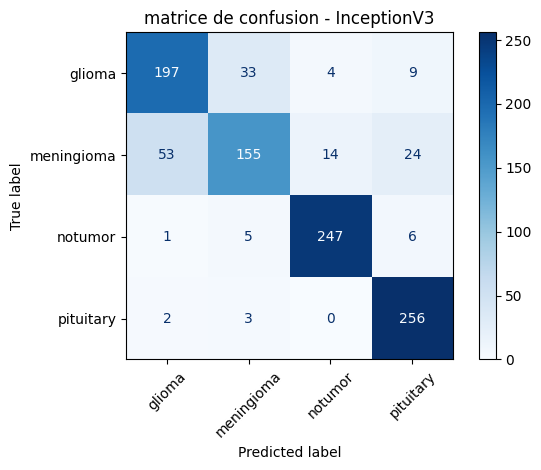

In [56]:
plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("matrice de confusion - InceptionV3")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [57]:
FINAL_MODEL_PATH = MODEL_DIR / "inceptionv3_final.keras"

model.save(FINAL_MODEL_PATH)

print("modele final sauvegarde :", FINAL_MODEL_PATH)

modele final sauvegarde : /kaggle/working/brainscan/models/inceptionv3_final.keras


In [58]:
for folder in [MODEL_DIR, REPORT_DIR]:
    print(f"\n{folder.name}/")

    for file in sorted(folder.iterdir()):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"- {file.name} ({size_mb:.2f} MB)")


models/
- inceptionv3_best.keras (84.31 MB)
- inceptionv3_final.keras (123.65 MB)
- inceptionv3_finetuned_best.keras (123.65 MB)
- inceptionv3_finetuning.csv (0.00 MB)
- inceptionv3_training.csv (0.00 MB)

report/
- classification_report.txt (0.00 MB)
- confusion_matrix.png (0.12 MB)
- test_metrics.csv (0.00 MB)
- test_predictions.csv (0.12 MB)
